# ConvNeXt-Base: Cow Lumpy Skin (Class_1 vs Class_2)

Fine-tunes a pretrained **ConvNeXt-Base** (ImageNet-22k → 1k weights via `timm`) for binary classification at **640×640**, tuned for the **Colab free tier (Tesla T4, 16 GB)**.

**Before running:** `Runtime → Change runtime type → T4 GPU`.

**Expected layout on Google Drive:**
```
MyDrive/Cow_lumpy_skin/
├── Class_1/        # training images
├── Class_2/        # training images
└── val/
    ├── Class_1/    # validation images
    └── Class_2/    # validation images
```
There is **no automatic train/test split**: training uses `Class_1` + `Class_2`, validation uses `val/`.

At 640 px ConvNeXt-Base needs a lot of GPU memory, so **gradient checkpointing** is enabled by default (trades ~25-35% speed for a large memory saving). A memory dry-run cell is included so you can see the real peak usage before training.

In [1]:
!nvidia-smi
!pip install -q timm scikit-learn

Wed Oct 14 21:04:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, random, time, copy, math, shutil
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')   # reduces GPU memory fragmentation
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import timm
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(42)

assert torch.cuda.is_available(), "No GPU found. Runtime > Change runtime type > T4 GPU"
device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__, "| timm", timm.__version__)

GPU: Tesla T4 | torch 2.11.0+cu130 | timm 1.0.30


## 1. Configuration & data

In [17]:
from google.colab import drive
drive.mount('/content/drive')

DATA_ROOT = '/content/drive/MyDrive/Cow_lumpy_skin'
os.chdir(DATA_ROOT)
print("Contents:", os.listdir(DATA_ROOT))

# Checkpoints / plots are saved on Drive so they survive disconnects
OUT_DIR = os.path.join(DATA_ROOT, 'runs_convnext')
os.makedirs(OUT_DIR, exist_ok=True)

# ---- Hyperparameters ----
MODEL_NAME      = 'convnext_base.fb_in22k_ft_in1k'   # alt: 'convnext_base.fb_in1k'
IMG_SIZE        = 640
BATCH_SIZE      = 20 #12          # 10 or 16
EPOCHS          = 120 #200
PATIENCE        = 30          # early stopping on val loss
LR_BACKBONE     = 5e-5
LR_HEAD         = 5e-4
WEIGHT_DECAY    = 0.05
WARMUP_EPOCHS   = 3
DROP_PATH       = 0.1
LABEL_SMOOTH    = 0.1
NUM_WORKERS     = 0
GRAD_CHECKPOINT = True        # strongly recommended at 640px on a 16 GB T4
RESUME          = True        # resume from OUT_DIR/last.pt if it exists

CLASS_NAMES = ['Class_1', 'Class_2']     # index 0 = Class_1, index 1 = Class_2
EXTS = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Copy only the data folders to Colab's local disk (reading from Drive every epoch is slow)
LOCAL_DIR = '/content/data'
for sub in ['Class_1', 'Class_2', 'val']:
    src, dst = os.path.join(DATA_ROOT, sub), os.path.join(LOCAL_DIR, sub)
    assert os.path.isdir(src), f"Missing folder: {src}"
    if not os.path.isdir(dst):
        shutil.copytree(src, dst)

def collect(root):
    paths, labels = [], []
    for label, cname in enumerate(CLASS_NAMES):
        folder = os.path.join(root, cname)
        assert os.path.isdir(folder), f"Missing folder: {folder}"
        for r, _, files in os.walk(folder):
            for f in sorted(files):
                if f.lower().endswith(EXTS):
                    paths.append(os.path.join(r, f)); labels.append(label)
    return paths, labels

tr_p, tr_l = collect(LOCAL_DIR)                       # Class_1, Class_2
va_p, va_l = collect(os.path.join(LOCAL_DIR, 'val'))  # val/Class_1, val/Class_2
assert len(tr_p) > 0 and len(va_p) > 0, "Empty train or val set"
print("train:", {c: tr_l.count(i) for i, c in enumerate(CLASS_NAMES)}, "| total", len(tr_p))
print("val  :", {c: va_l.count(i) for i, c in enumerate(CLASS_NAMES)}, "| total", len(va_p))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Contents: ['Class_2', 'val', 'Class_1', 'LSD_ConvNeXt_Base_Colab.ipynb', 'runs_convnext', 'LSD_v3_ConvNeXt_Base_Colab.ipynb']
train: {'Class_1': 48, 'Class_2': 52} | total 100
val  : {'Class_1': 16, 'Class_2': 19} | total 35


class weights: [1.0416666269302368, 0.9615384340286255] | steps/epoch: 5


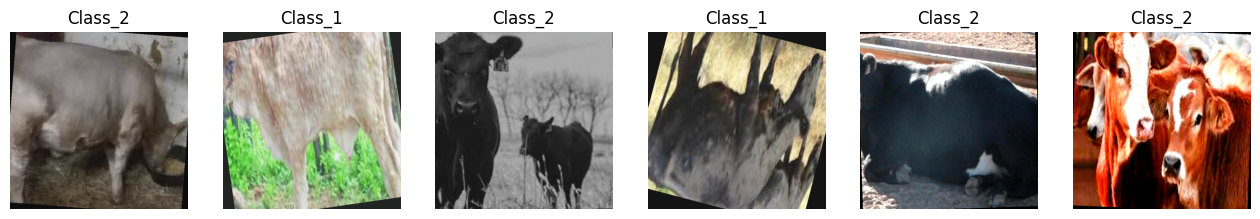

In [18]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.2, 0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
# Resize the whole image (no center crop) so lesions near the edges are never cut off
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class ImgDS(Dataset):
    def __init__(self, paths, labels, tf):
        self.paths, self.labels, self.tf = paths, labels, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            img = Image.open(self.paths[i]).convert('RGB')
        except Exception:                      # unreadable file -> blank image instead of crashing
            img = Image.new('RGB', (IMG_SIZE, IMG_SIZE))
        return self.tf(img), self.labels[i]

train_dl = DataLoader(ImgDS(tr_p, tr_l, train_tf), batch_size=BATCH_SIZE, shuffle=True,
                      num_workers=NUM_WORKERS, pin_memory=True,
                      drop_last=len(tr_p) > BATCH_SIZE, persistent_workers=NUM_WORKERS > 0)
val_dl   = DataLoader(ImgDS(va_p, va_l, eval_tf), batch_size=BATCH_SIZE, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)

counts = np.bincount(tr_l, minlength=2)
class_w = torch.tensor(len(tr_l) / (2.0 * counts), dtype=torch.float32, device=device)
print("class weights:", class_w.tolist(), "| steps/epoch:", len(train_dl))

xb, yb = next(iter(train_dl))
fig, axs = plt.subplots(1, min(6, len(xb)), figsize=(16, 3))
for i, ax in enumerate(np.atleast_1d(axs)):
    img = xb[i].permute(1,2,0).numpy() * np.array(STD) + np.array(MEAN)
    ax.imshow(np.clip(img, 0, 1)); ax.set_title(CLASS_NAMES[yb[i]]); ax.axis('off')
plt.show()

## 2. Model

In [19]:
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=2, drop_path_rate=DROP_PATH)
if GRAD_CHECKPOINT:
    model.set_grad_checkpointing(True)
model = model.to(device).to(memory_format=torch.channels_last)
print(f"Params: {sum(p.numel() for p in model.parameters())/1e6:.1f}M | grad checkpointing: {GRAD_CHECKPOINT}")

head_params = list(model.get_classifier().parameters())
head_ids = {id(p) for p in head_params}
backbone_params = [p for p in model.parameters() if id(p) not in head_ids]

optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': LR_BACKBONE},
    {'params': head_params,     'lr': LR_HEAD},
], weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_dl)
total_steps  = EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch
def lr_lambda(step):
    if step < warmup_steps: return (step + 1) / warmup_steps
    p = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * p)) * 0.99 + 0.01
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=LABEL_SMOOTH)
scaler = torch.amp.GradScaler('cuda')

Params: 87.6M | grad checkpointing: True


### GPU memory dry-run (optional but recommended)
One forward + backward pass at your `BATCH_SIZE` on random data, to see the real peak GPU memory before committing to training. (AdamW's optimizer state adds roughly 0.7 GB more once training starts.) If this raises an out-of-memory error, lower `BATCH_SIZE`, make sure `GRAD_CHECKPOINT = True`, and re-run from the config cell.

In [20]:
import psutil
torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
model.train()
x = torch.randn(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE, device=device).to(memory_format=torch.channels_last)
y = torch.randint(0, 2, (BATCH_SIZE,), device=device)
with torch.autocast('cuda', dtype=torch.float16):
    loss = criterion(model(x), y)
loss.backward()
optimizer.zero_grad(set_to_none=True)
total = torch.cuda.get_device_properties(0).total_memory / 1024**3
print(f"Peak GPU memory (batch {BATCH_SIZE}, {IMG_SIZE}px): {torch.cuda.max_memory_allocated()/1024**3:.2f} GB "
      f"(reserved {torch.cuda.max_memory_reserved()/1024**3:.2f} GB of {total:.1f} GB)")
print(f"System RAM in use: {psutil.virtual_memory().used/1024**3:.2f} GB of {psutil.virtual_memory().total/1024**3:.1f} GB")
del x, y, loss; torch.cuda.empty_cache()

Peak GPU memory (batch 20, 640px): 4.69 GB (reserved 5.48 GB of 14.6 GB)
System RAM in use: 4.55 GB of 12.7 GB


### One-time cleanup (optional)
Lists any leftover files in `runs_convnext` (old `.tmp` files, `best.pt`/`last.pt`, copies like `... (1).pth`). Set `CLEAN_UP = True` to delete them. Deleted files go to Drive's Trash, so empty the Trash once in the Drive web UI afterwards.

In [21]:
CLEAN_UP = False
keep = {'convnext_cattle_best.pth', 'convnext_cattle_ep.pth', 'training_curves.png', 'val_results.png'}
extras = [f for f in sorted(os.listdir(OUT_DIR)) if f not in keep]
print("Leftover files in", OUT_DIR, ":", extras if extras else "none")
if CLEAN_UP:
    for f in extras:
        os.remove(os.path.join(OUT_DIR, f)); print("deleted", f)

Leftover files in /content/drive/MyDrive/Cow_lumpy_skin/runs_convnext : none


## 3. Training
Mixed precision, gradient clipping, early stopping (patience 15 on val loss), and exactly two checkpoint files (saved locally first, then copied to Drive in the background, overwriting the same two Drive files in place so no extra copies or Trash entries pile up): `convnext_cattle_best.pth` (updated only when val loss improves) and `convnext_cattle_ep.pth` (updated only when it does not).

In [22]:
def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in loader:
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast('cuda', dtype=torch.float16):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

import threading, subprocess

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
best_val_loss, bad_epochs, start_epoch = float('inf'), 0, 0

# ---- Checkpoints: exactly two files ----
#   convnext_cattle_best.pth -> overwritten only when val loss improves
#   convnext_cattle_ep.pth   -> overwritten only when val loss does NOT improve
# Each save goes to fast LOCAL disk first (takes a second or two), then is copied to Drive
# in a background thread so slow Drive writes never block training.
LOCAL_CKPT_DIR = '/content/ckpt'
os.makedirs(LOCAL_CKPT_DIR, exist_ok=True)
BEST_NAME, EP_NAME = 'convnext_cattle_best.pth', 'convnext_cattle_ep.pth'
LOCAL_BEST, LOCAL_EP = f'{LOCAL_CKPT_DIR}/{BEST_NAME}', f'{LOCAL_CKPT_DIR}/{EP_NAME}'
BEST_PATH, EP_PATH   = f'{OUT_DIR}/{BEST_NAME}', f'{OUT_DIR}/{EP_NAME}'     # Drive copies

saved_epoch, synced_epoch, _threads = {}, {}, {}

def save_local(name, epoch):
    state = {'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
             'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
             'history': history, 'best_val_loss': best_val_loss, 'bad_epochs': bad_epochs,
             'epoch': epoch, 'class_names': CLASS_NAMES, 'model_name': MODEL_NAME, 'img_size': IMG_SIZE}
    path = f'{LOCAL_CKPT_DIR}/{name}'
    torch.save(state, path + '.tmp')
    os.replace(path + '.tmp', path)          # atomic swap: never a half-written file
    saved_epoch[name] = epoch

def _copy_to_drive(name, epoch):
    src, dst = f'{LOCAL_CKPT_DIR}/{name}', f'{OUT_DIR}/{name}'
    try:
        # Overwrite the SAME Drive file in place. No temp file, no rename, no delete,
        # so Drive never creates extra copies or sends anything to Trash.
        shutil.copyfile(src, dst)
        synced_epoch[name] = epoch
    except Exception as e:
        print(f"[Drive sync of {name} failed: {e}]")

def sync_to_drive(name):
    t = _threads.get(name)
    if t is not None and t.is_alive():
        return                               # previous upload still running; the local file already has the latest
    t = threading.Thread(target=_copy_to_drive, args=(name, saved_epoch[name]), daemon=True)
    _threads[name] = t; t.start()

def final_sync():
    for t in _threads.values(): t.join()
    for name in (BEST_NAME, EP_NAME):
        if name in saved_epoch and synced_epoch.get(name) != saved_epoch[name]:
            _copy_to_drive(name, saved_epoch[name])
    print("Drive checkpoints are up to date.")

def gpu_stats():
    try:
        out = subprocess.check_output(['nvidia-smi', '--query-gpu=temperature.gpu,clocks.sm,clocks.max.sm,power.draw',
                                       '--format=csv,noheader,nounits']).decode().strip()
        t, c, cm, pw = [v.strip() for v in out.split(',')]
        return f"{t}C {c}/{cm}MHz {float(pw):.0f}W"
    except Exception:
        return ''

# Resume from whichever checkpoint (local or Drive) holds the most recent epoch
if RESUME:
    latest = None
    for pth in (LOCAL_BEST, LOCAL_EP, BEST_PATH, EP_PATH):
        if os.path.exists(pth):
            try:
                c = torch.load(pth, map_location='cpu')
            except Exception as e:                  # e.g. a Drive upload cut off by a disconnect
                print(f"Skipping unreadable checkpoint {pth}: {e}"); continue
            if latest is None or c['epoch'] > latest['epoch']:
                latest = c
            del c
    if latest is not None:
        model.load_state_dict(latest['model']); optimizer.load_state_dict(latest['optimizer'])
        scheduler.load_state_dict(latest['scheduler']); scaler.load_state_dict(latest['scaler'])
        history, best_val_loss, bad_epochs = latest['history'], latest['best_val_loss'], latest['bad_epochs']
        start_epoch = latest['epoch'] + 1
        print(f"Resumed from epoch {start_epoch}")
        del latest

torch.cuda.reset_peak_memory_stats()
try:
    for epoch in range(start_epoch, EPOCHS):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(train_dl, True)
        t1 = time.time()
        va_loss, va_acc = run_epoch(val_dl, False)
        t2 = time.time()
        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)): history[k].append(v)

        improved = va_loss < best_val_loss
        if improved:
            best_val_loss, bad_epochs = va_loss, 0
        else:
            bad_epochs += 1
        name = BEST_NAME if improved else EP_NAME
        save_local(name, epoch)
        sync_to_drive(name)
        t3 = time.time()

        print(f"Epoch {epoch+1:03d}/{EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"time: train {t1-t0:.0f}s val {t2-t1:.0f}s save {t3-t2:.1f}s | "
              f"peak GPU {torch.cuda.max_memory_allocated()/1024**3:.1f} GB | {gpu_stats()}"
              f"{'  <- new best (best file)' if improved else '  (ep file)'}")
        if bad_epochs >= PATIENCE:
            print(f"Early stopping (no val-loss improvement for {PATIENCE} epochs)."); break
finally:
    final_sync()      # also runs if you interrupt the cell, so Drive always gets the latest files

Resumed from epoch 86
Epoch 087/120 | train loss 0.1998 acc 1.0000 | val loss 0.2003 acc 1.0000 | time: train 17s val 1s save 7.1s | peak GPU 5.4 GB | 74C 585/1590MHz 31W  (ep file)
Epoch 088/120 | train loss 0.1995 acc 1.0000 | val loss 0.2002 acc 1.0000 | time: train 18s val 1s save 10.2s | peak GPU 5.4 GB | 75C 585/1590MHz 32W  (ep file)
Epoch 089/120 | train loss 0.1995 acc 1.0000 | val loss 0.2001 acc 1.0000 | time: train 21s val 1s save 4.1s | peak GPU 5.4 GB | 77C 585/1590MHz 32W  <- new best (best file)
Epoch 090/120 | train loss 0.1996 acc 1.0000 | val loss 0.2001 acc 1.0000 | time: train 19s val 2s save 8.5s | peak GPU 5.4 GB | 74C 585/1590MHz 32W  (ep file)
Epoch 091/120 | train loss 0.1995 acc 1.0000 | val loss 0.2001 acc 1.0000 | time: train 19s val 1s save 5.7s | peak GPU 5.4 GB | 77C 585/1590MHz 32W  <- new best (best file)
Epoch 092/120 | train loss 0.1993 acc 1.0000 | val loss 0.2001 acc 1.0000 | time: train 21s val 1s save 20.0s | peak GPU 5.4 GB | 72C 585/1590MHz 31W

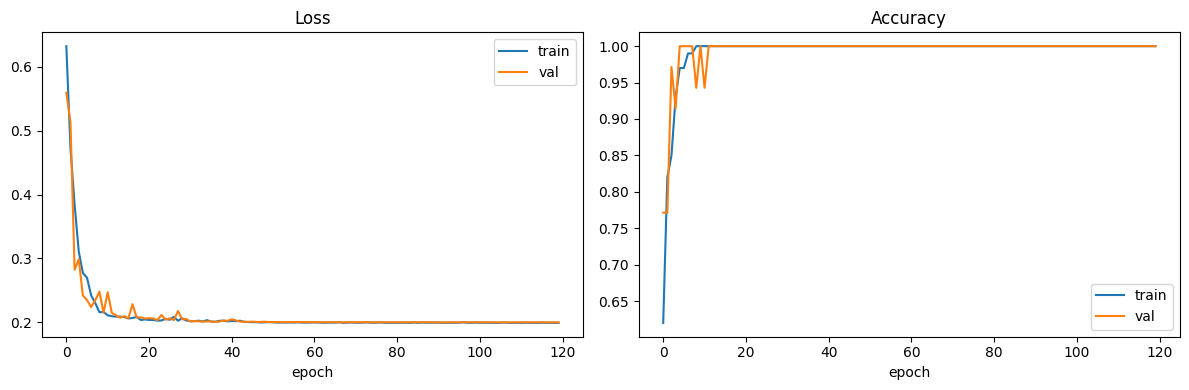

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(history['train_acc'], label='train'); ax[1].plot(history['val_acc'], label='val')
ax[1].set_title('Accuracy'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150); plt.show()

## 4. Evaluation on the validation set (best checkpoint)
Note: since validation data also picks the best epoch and triggers early stopping, these numbers are slightly optimistic. For an unbiased estimate, keep a separate test folder that is never used during training.

              precision    recall  f1-score   support

     Class_1     1.0000    1.0000    1.0000        16
     Class_2     1.0000    1.0000    1.0000        19

    accuracy                         1.0000        35
   macro avg     1.0000    1.0000    1.0000        35
weighted avg     1.0000    1.0000    1.0000        35

ROC AUC (Class_2 as positive): 1.0


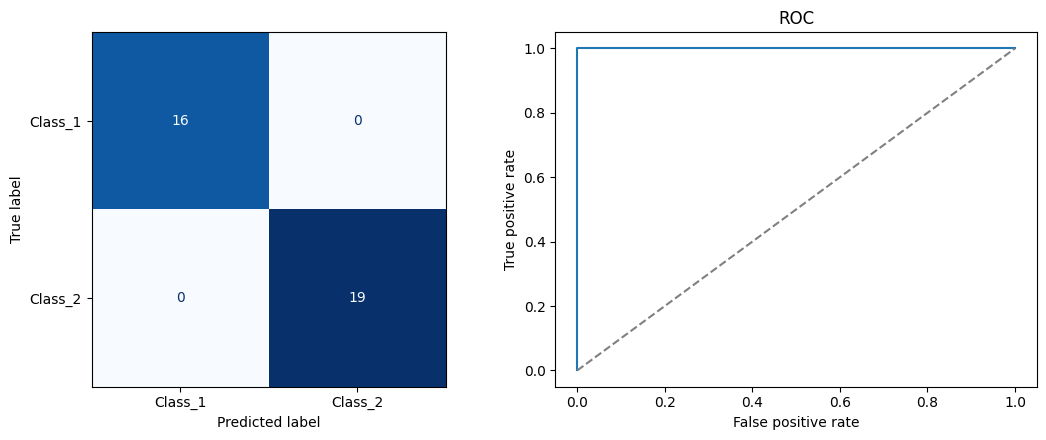

In [24]:
ck = torch.load(LOCAL_BEST if os.path.exists(LOCAL_BEST) else BEST_PATH, map_location=device)
model.load_state_dict(ck['model']); model.eval()

all_probs, all_labels = [], []
with torch.no_grad():
    for x, y in val_dl:
        x = x.to(device).to(memory_format=torch.channels_last)
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(x)
        all_probs.append(F.softmax(out.float(), 1).cpu().numpy()); all_labels.append(y.numpy())
probs, y_true = np.concatenate(all_probs), np.concatenate(all_labels)
y_pred = probs.argmax(1)

print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
if len(set(y_true)) == 2:
    print("ROC AUC (Class_2 as positive):", round(roc_auc_score(y_true, probs[:, 1]), 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=[0, 1]), display_labels=CLASS_NAMES).plot(ax=ax[0], cmap='Blues', colorbar=False)
if len(set(y_true)) == 2:
    fpr, tpr, _ = roc_curve(y_true, probs[:, 1])
    ax[1].plot(fpr, tpr); ax[1].plot([0,1],[0,1],'--', c='gray')
    ax[1].set_xlabel('False positive rate'); ax[1].set_ylabel('True positive rate'); ax[1].set_title('ROC')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/val_results.png', dpi=150); plt.show()

## 5. Inference on a new image

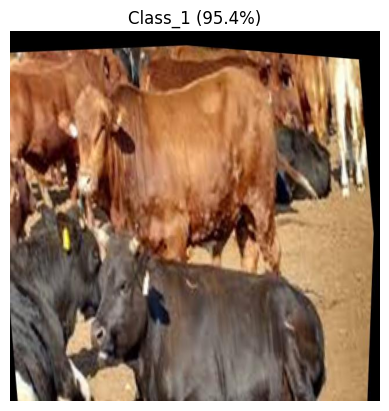

('Class_1', array([0.9539661, 0.0460339], dtype=float32))

In [25]:
def predict(image_path, show=True):
    img = Image.open(image_path).convert('RGB')
    x = eval_tf(img).unsqueeze(0).to(device).to(memory_format=torch.channels_last)
    model.eval()
    with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
        p = F.softmax(model(x).float(), 1)[0].cpu().numpy()
    label = CLASS_NAMES[p.argmax()]
    if show:
        plt.imshow(img); plt.axis('off')
        plt.title(f"{label} ({p.max()*100:.1f}%)"); plt.show()
    return label, p

predict(va_p[0])

# Or upload your own:
# from google.colab import files
# up = files.upload(); predict(list(up.keys())[0])

## Tips
- **CUDA out of memory?** Keep `GRAD_CHECKPOINT = True`, set `BATCH_SIZE = 10` (or lower).
- **Drive storage / Trash:** the notebook never creates temp files, renames or deletes anything on Drive; it only overwrites `convnext_cattle_best.pth` and `convnext_cattle_ep.pth` in place. Drive may still keep a few older *versions* of an overwritten file (right-click the file > File information > Manage versions).
- **Epochs getting slower?** The log prints train / val / save time plus GPU temperature, clock speed and power for every epoch, so you can see which part slows down.
- **Very small dataset?** With a few dozen training images, an 89M-parameter model overfits easily. Watch the gap between train and val accuracy; `convnext_small` / `convnext_tiny` (`.fb_in22k_ft_in1k`) are faster and often just as good here.
- **Disconnected?** Re-run all cells; with `RESUME = True` training continues from whichever checkpoint file holds the latest epoch.
- Checkpoints live in `Cow_lumpy_skin/runs_convnext/`. Each is a full checkpoint (weights + optimizer state, roughly 1 GB). Best weights for inference are in `convnext_cattle_best.pth` under the `'model'` key.